# CitizenTech — Alerta de calor extremo
**Global Solution 2026.2 · FIAP · Engenharia de Software (3º ano) · Inteligência Artificial & Machine Learning**

Grupo: Henrique Sanches (RM557959) · João Pedro Kraide Máximo (RM563166) · Douglas dos Santos Melo (RM556439) · Nicolas Caciolato Reis (RM556506) · Matheus Marcelino Dantas da Silva (RM556332)

**Como executar:** coloque os CSV do INMET em `ml/dados/raw/` (veja `dados/README.md`) e use *Kernel → Restart & Run All*. O notebook gera as figuras em `figuras/` e as tabelas em `resultados/`.

**Roteiro:** 1) Problema e dados reais → 2) Preparação e divisão treino/teste → 3) Modelo e treino com hiperparâmetros → 4) Resultados em treino e teste → 5) Conclusão para o cidadão.

## 1. Problema e dados reais

**Cidade:** Osasco (SP). **Cidadão:** idosos e trabalhadores de rua. **Problema:** eles não recebem, com um dia de antecedência, um aviso confiável de calor extremo.

**Pergunta de ML (classificação binária):** com as medições de hoje e dos últimos dias, **amanhã será um dia de calor extremo**, isto é, a temperatura máxima será igual ou maior que o limiar (percentil 90 das máximas do período de treino)? Dias de calor extremo seguidos formam uma **onda de calor**; a seção 2 mostra por que a definição formal de onda não serve como alvo do modelo com 4 anos de dados.

**Dados:** INMET, dados históricos horários da estação automática mais próxima de Osasco: São Paulo – Mirante (A701), a cerca de 18 km, segundo o portal do INMET (https://portal.inmet.gov.br/dadoshistoricos). Dados reais e públicos, sem nenhuma simulação.

In [1]:
from pathlib import Path
import re, json, unicodedata, warnings, zipfile, io, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             precision_recall_curve, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})

# ---------------- CONFIGURAÇÃO (ajuste aqui se mudar de cidade/estação) ----------------
CIDADE = "Osasco (SP)"
ESTACAO = "A701"                    # código INMET da estação automática usada
ESTACAO_DESC = "A701 (São Paulo – Mirante), a cerca de 18 km de Osasco"   # estação do INMET mais próxima, segundo o portal
ANOS = list(range(2022, 2026))      # anos usados (2022 a 2025)
PERCENTIL_CALOR = 90                # define "calor extremo" (calculado só no treino)
MIN_HORAS_VALIDAS = 18              # dia com menos horas válidas é descartado
TEST_FRAC = 0.20                    # últimos 20% dos dias = teste (cronológico)
# ---------------------------------------------------------------------------------------

BASE = Path.cwd()
ROOT = BASE.parent if BASE.name == "ml" else BASE
DATA_DIR, FIG_DIR, RES_DIR = BASE / "dados" / "raw", BASE / "figuras", BASE / "resultados"
for d in (DATA_DIR, FIG_DIR, RES_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("Pasta de trabalho:", BASE.name)

Pasta de trabalho: ml


In [2]:
# (Opcional) tenta baixar do portal do INMET os anos que ainda não estão em dados/raw.
# Se falhar (o portal às vezes bloqueia scripts), baixe manualmente e coloque os CSV em dados/raw/.
def tem_arquivo(ano):
    return any(p.suffix.lower() == ".csv" and ESTACAO in p.name.upper() and str(ano) in p.name
               for p in DATA_DIR.rglob("*"))

def baixar_ano(ano):
    url = f"https://portal.inmet.gov.br/uploads/dadoshistoricos/{ano}.zip"
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=120) as r:
        zf = zipfile.ZipFile(io.BytesIO(r.read()))
    achou = False
    for nome in zf.namelist():
        base = Path(nome).name
        if ESTACAO in base.upper() and base.lower().endswith(".csv"):
            (DATA_DIR / base).write_bytes(zf.read(nome)); achou = True
    return achou

for ano in ANOS:
    if tem_arquivo(ano):
        continue
    try:
        print(ano, "->", "baixado" if baixar_ano(ano) else "estação não encontrada no zip")
    except Exception as e:
        print(ano, "-> falha no download:", type(e).__name__, "(baixe manualmente)")

In [3]:
def norm(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().upper().strip()
    return re.sub(r"\s+", " ", s)

# Os nomes das colunas do INMET mudam um pouco entre anos; casamos por padrão do nome normalizado.
PADROES = {
    "temp_ar":  lambda c: "BULBO SECO" in c,
    "temp_max": lambda c: c.startswith("TEMPERATURA MAXIMA"),
    "temp_min": lambda c: c.startswith("TEMPERATURA MINIMA"),
    "umidade":  lambda c: c.startswith("UMIDADE RELATIVA DO AR"),
    "chuva":    lambda c: c.startswith("PRECIPITACAO TOTAL"),
    "radiacao": lambda c: c.startswith("RADIACAO GLOBAL"),
    "vento":    lambda c: c.startswith("VENTO, VELOCIDADE"),
    "pressao":  lambda c: c.startswith("PRESSAO ATMOSFERICA AO NIVEL"),
}

def extrair_hora(v):
    s = str(v).strip()
    try:
        if ":" in s:
            return int(s.split(":")[0])
        m = re.search(r"\d+", s)
        return int(m.group().zfill(4)[:2]) if m else np.nan
    except ValueError:
        return np.nan

def ler_inmet(caminho):
    """Lê um CSV horário do INMET (8 linhas de metadados, separador ';', decimal ',')."""
    try:
        df = pd.read_csv(caminho, sep=";", skiprows=8, decimal=",", encoding="utf-8", low_memory=False)
    except UnicodeDecodeError:
        df = pd.read_csv(caminho, sep=";", skiprows=8, decimal=",", encoding="latin-1", low_memory=False)
    df = df.loc[:, [c for c in df.columns if not str(c).startswith("Unnamed")]]
    df.columns = [norm(c) for c in df.columns]
    col_data = next(c for c in df.columns if c.startswith("DATA"))
    col_hora = next(c for c in df.columns if c.startswith("HORA"))

    d = df[col_data].astype(str).str.strip().str.replace("/", "-", regex=False)
    data = pd.to_datetime(d, format="%Y-%m-%d", errors="coerce")
    if data.isna().mean() > 0.5:
        data = pd.to_datetime(d, format="%d-%m-%Y", errors="coerce")
    hora = df[col_hora].map(extrair_hora)
    ts_utc = data + pd.to_timedelta(hora, unit="h")

    out = pd.DataFrame({"ts_local": ts_utc - pd.Timedelta(hours=3)})   # UTC -> horário de Brasília
    for chave, regra in PADROES.items():
        col = next((c for c in df.columns if regra(c)), None)
        if col is None:
            out[chave] = np.nan
            continue
        v = pd.to_numeric(df[col].astype(str).str.replace(",", ".", regex=False), errors="coerce")
        out[chave] = v.where(v > -9990)       # -9999 = ausente no INMET
    return out.dropna(subset=["ts_local"])

arquivos = sorted(p for p in DATA_DIR.rglob("*")
                  if p.is_file() and p.suffix.lower() == ".csv" and ESTACAO in p.name.upper())
if not arquivos:
    raise FileNotFoundError(
        f"Nenhum CSV da estação {ESTACAO} em {DATA_DIR}. Veja dados/README.md para baixar os dados do INMET.")
print(f"{len(arquivos)} arquivo(s) da estação {ESTACAO}:")
for p in arquivos:
    print(" -", p.name)

horario = (pd.concat([ler_inmet(p) for p in arquivos], ignore_index=True)
             .drop_duplicates(subset="ts_local").sort_values("ts_local").reset_index(drop=True))
if horario["temp_ar"].notna().sum() == 0:
    raise ValueError("Não encontrei a coluna de temperatura. Colunas lidas: " + ", ".join(norm(c) for c in
                     pd.read_csv(arquivos[0], sep=";", skiprows=8, encoding="latin-1", nrows=1).columns))
print(f"\nRegistros horários: {len(horario):,}  |  de {horario.ts_local.min():%d/%m/%Y} a {horario.ts_local.max():%d/%m/%Y}")
horario.head()

4 arquivo(s) da estação A701:
 - INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2022_A_31-12-2022.CSV
 - INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2023_A_31-12-2023.CSV
 - INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2024_A_31-12-2024.CSV
 - INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2025_A_31-12-2025.CSV



Registros horários: 35,064  |  de 31/12/2021 a 31/12/2025


,ts_local,temp_ar,temp_max,temp_min,umidade,chuva,radiacao,vento,pressao
0,2021-12-31 21:00:00,19.3,19.4,19.2,92.0,0.0,NaN,0.7,920.5
1,2021-12-31 22:00:00,19.1,19.4,19.1,93.0,0.0,NaN,0.1,920.8
2,2021-12-31 23:00:00,19.0,19.1,18.8,93.0,0.0,NaN,0.0,920.8
3,2022-01-01 00:00:00,18.7,19.0,18.7,93.0,0.0,NaN,0.0,920.4
4,2022-01-01 01:00:00,18.5,18.7,18.5,93.0,0.0,NaN,0.0,919.7


In [4]:
# Agregação diária (horário local)
h = horario.copy()
h["dia"] = h["ts_local"].dt.floor("D")
g = h.groupby("dia")
diario = pd.DataFrame({
    "horas_validas": g["temp_ar"].count(),
    "tmax": g[["temp_ar", "temp_max"]].max().max(axis=1),
    "tmin": g[["temp_ar", "temp_min"]].min().min(axis=1),
    "tmean": g["temp_ar"].mean(),
    "umid_mean": g["umidade"].mean(),
    "umid_min": g["umidade"].min(),
    "chuva": g["chuva"].sum(min_count=1),
    "radiacao": g["radiacao"].sum(min_count=1),
    "vento": g["vento"].mean(),
    "pressao": g["pressao"].mean(),
})
diario = diario[diario["horas_validas"] >= MIN_HORAS_VALIDAS].drop(columns="horas_validas")
diario = diario.loc[f"{ANOS[0]}-01-01":f"{ANOS[-1]}-12-31"]
diario = diario.reindex(pd.date_range(diario.index.min(), diario.index.max(), freq="D"))
diario.index.name = "dia"

cobertura = diario["tmax"].notna().groupby(diario.index.year).agg(["sum", "size"])
cobertura.columns = ["dias_validos", "dias_no_ano"]
cobertura["%"] = (100 * cobertura["dias_validos"] / cobertura["dias_no_ano"]).round(1)
print("Cobertura de dias válidos por ano:")
display(cobertura.T)

# lacunas curtas (até 2 dias) são interpoladas; o resto fica ausente e será descartado
diario = diario.interpolate(limit=2, limit_area="inside")
diario.describe().round(2)

Cobertura de dias válidos por ano:


dia,2022,2023,2024,2025
dias_validos,365.0,352.0,365.0,364.0
dias_no_ano,365.0,365.0,366.0,365.0
%,100.0,96.4,99.7,99.7


,tmax,tmin,tmean,umid_mean,umid_min,chuva,radiacao,vento,pressao
count,1460.00,1460.00,1460.00,1460.00,1460.00,1448.00,1460.00,1460.00,1460.00
mean,26.94,16.88,20.80,68.24,44.44,4.31,16679.46,1.77,927.11
std,4.48,3.13,3.45,10.94,15.26,10.65,6220.63,0.61,3.45
min,12.30,5.70,9.53,28.33,12.00,0.00,1359.10,0.11,914.96
25%,24.10,14.70,18.47,62.27,33.00,0.00,12707.80,1.37,924.69
50%,27.35,17.20,21.07,69.54,43.00,0.00,17250.45,1.72,926.85
75%,30.30,19.40,23.34,75.88,55.00,2.60,21043.60,2.13,929.48
max,37.50,24.10,30.43,94.08,91.00,125.60,31149.40,6.11,937.42


## 2. Preparação dos dados e divisão treino/teste

- **Features** só com informação de hoje e do passado (defasagens e médias móveis da máxima, amplitude, chuva em 7 dias, sazonalidade).
- **Alvo:** a máxima de **amanhã** é ≥ limiar de calor extremo?
- **Divisão cronológica** (sem embaralhar): evita “ver o futuro” no treino. O **limiar é calculado só no treino**.

In [5]:
d = diario.copy()
d["doy_sin"] = np.sin(2 * np.pi * d.index.dayofyear / 365.25)
d["doy_cos"] = np.cos(2 * np.pi * d.index.dayofyear / 365.25)
for k in (1, 2, 3):
    d[f"tmax_lag{k}"] = d["tmax"].shift(k)
d["tmax_med3"] = d["tmax"].rolling(3).mean()
d["tmax_med7"] = d["tmax"].rolling(7).mean()
d["tmax_delta1"] = d["tmax"].diff(1)
d["amplitude"] = d["tmax"] - d["tmin"]
d["chuva_7d"] = d["chuva"].rolling(7, min_periods=3).sum()
d["alvo_tmax_amanha"] = d["tmax"].shift(-1)

candidatas = ["tmax", "tmin", "tmean", "umid_mean", "umid_min", "chuva", "radiacao", "vento", "pressao",
              "doy_sin", "doy_cos", "tmax_lag1", "tmax_lag2", "tmax_lag3", "tmax_med3", "tmax_med7",
              "tmax_delta1", "amplitude", "chuva_7d"]
# descarta variável com muita falta de dado (ex.: sensor que não existia em alguns anos)
FEATURES_BASE = [c for c in candidatas if d[c].isna().mean() < 0.30]
print("Variáveis descartadas por falta de dados:", sorted(set(candidatas) - set(FEATURES_BASE)) or "nenhuma")

d = d.dropna(subset=FEATURES_BASE + ["alvo_tmax_amanha"])
corte = d.index[int(len(d) * (1 - TEST_FRAC))]
treino_idx = d.index < corte - pd.Timedelta(days=1)   # 1 dia de intervalo: o alvo do último dia de treino seria a máxima do 1º dia de teste

LIMIAR = float(d.loc[treino_idx, "alvo_tmax_amanha"].quantile(PERCENTIL_CALOR / 100))   # só no treino!

# Variáveis de "onda": quantos dias seguidos já estão acima do limiar até hoje (só passado)
quente = (diario["tmax"] >= LIMIAR)
bloco_id = (quente != quente.shift()).cumsum()
d["dias_seguidos_quente"] = quente.groupby(bloco_id).cumsum().where(quente, 0).reindex(d.index)
d["dias_quentes_7d"] = quente.astype(int).rolling(7).sum().reindex(d.index)
FEATURES = FEATURES_BASE + ["dias_seguidos_quente", "dias_quentes_7d"]

treino, teste = d[treino_idx], d[d.index >= corte]
y_tr = (treino["alvo_tmax_amanha"] >= LIMIAR).astype(int)
y_te = (teste["alvo_tmax_amanha"] >= LIMIAR).astype(int)
X_tr, X_te = treino[FEATURES], teste[FEATURES]

print(f"Dias utilizáveis: {len(d)}  |  treino: {len(treino)} (até {treino.index.max():%d/%m/%Y})  |  teste: {len(teste)} (a partir de {corte:%d/%m/%Y})")
print(f"Limiar de calor extremo (percentil {PERCENTIL_CALOR} do treino): {LIMIAR:.1f} °C")
print(f"Prevalência de dias extremos -> treino: {y_tr.mean():.1%}  |  teste: {y_te.mean():.1%}")

Variáveis descartadas por falta de dados: nenhuma
Dias utilizáveis: 1430  |  treino: 1143 (até 18/03/2025)  |  teste: 286 (a partir de 20/03/2025)
Limiar de calor extremo (percentil 90 do treino): 32.5 °C
Prevalência de dias extremos -> treino: 10.6%  |  teste: 7.7%


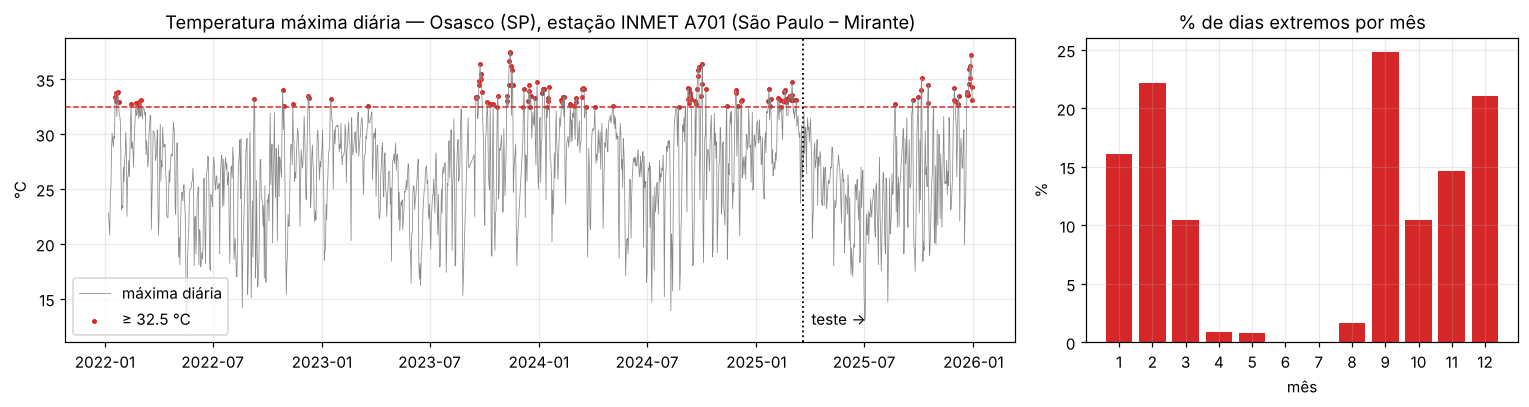

In [6]:
# EDA: série de máximas e sazonalidade dos dias extremos
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
ax[0].plot(d.index, d["tmax"], lw=.5, color="#888", label="máxima diária")
ext = d[d["tmax"] >= LIMIAR]
ax[0].scatter(ext.index, ext["tmax"], s=5, color="#d62728", label=f"≥ {LIMIAR:.1f} °C")
ax[0].axhline(LIMIAR, color="#d62728", ls="--", lw=1)
ax[0].axvline(corte, color="k", ls=":", lw=1.2); ax[0].text(corte, d["tmax"].min(), "  teste →", va="bottom")
ax[0].set_title(f"Temperatura máxima diária — {CIDADE}, estação INMET {ESTACAO} (São Paulo – Mirante)"); ax[0].set_ylabel("°C"); ax[0].legend(loc="lower left")
mes = (d["alvo_tmax_amanha"] >= LIMIAR).groupby(d.index.month).mean() * 100
ax[1].bar(mes.index, mes.values, color="#d62728"); ax[1].set_xticks(range(1, 13))
ax[1].set_title("% de dias extremos por mês"); ax[1].set_xlabel("mês"); ax[1].set_ylabel("%")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_serie_e_sazonalidade.png", bbox_inches="tight"); plt.show()

### Ondas de calor nos dados: quantos eventos existem?
Uma **onda de calor** é uma sequência de dias muito quentes. O critério da OMM, que o INMET segue, é máxima pelo menos 5 °C acima da média do mês por 5 dias ou mais (os avisos laranja do INMET usam 3 a 5 dias). Vamos contar quantos eventos assim existem nos 4 anos de dados, para decidir o que dá para modelar. A média mensal aqui é calculada com os 4 anos disponíveis (a norma oficial usa 30 anos), e este quadro é só descritivo.

,Definição de onda de calor,Eventos no total,Eventos no teste,Dias em onda
0,Oficial (OMM/INMET): ≥ 5 °C acima da média do ...,7,1,45
1,Aviso laranja (INMET): ≥ 5 °C acima da média d...,12,2,60
2,"Operacional (nossa): máxima ≥ 32.5 °C, por ≥ 3...",17,2,82


82 dos 147 dias extremos (56%) estão em sequências de 3 dias ou mais.


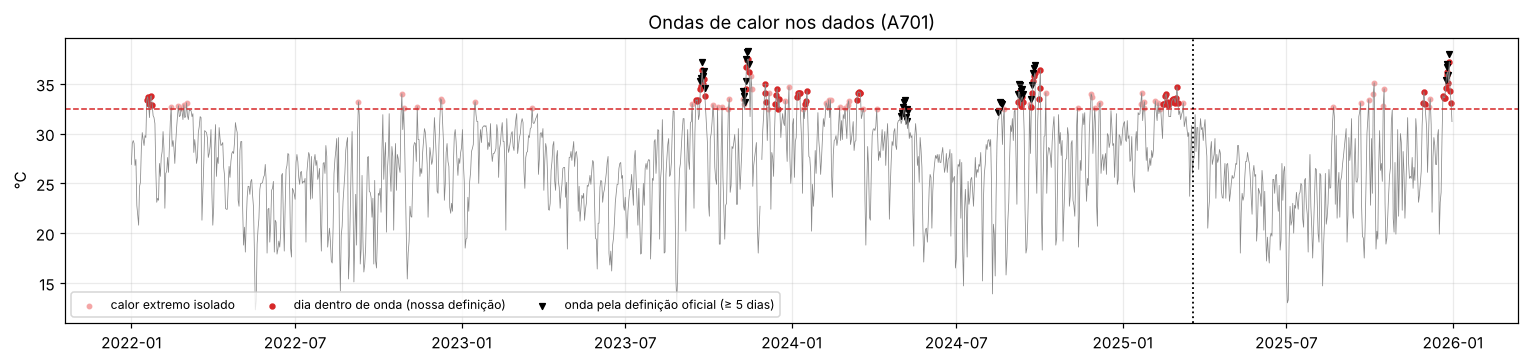

In [7]:
def dias_de_onda(quente_bool, min_dias):
    q = quente_bool.fillna(False).astype(bool)
    bloco = (q != q.shift()).cumsum()
    return q & (q.groupby(bloco).transform("sum") >= min_dias)

serie = diario["tmax"]
anomalia = serie - serie.groupby(serie.index.month).transform("mean")
NOME_OFICIAL = "Oficial (OMM/INMET): ≥ 5 °C acima da média do mês, por ≥ 5 dias"
NOME_LARANJA = "Aviso laranja (INMET): ≥ 5 °C acima da média do mês, por ≥ 3 dias"
NOME_OP = f"Operacional (nossa): máxima ≥ {LIMIAR:.1f} °C, por ≥ 3 dias"
definicoes = {NOME_OFICIAL: dias_de_onda(anomalia >= 5, 5),
              NOME_LARANJA: dias_de_onda(anomalia >= 5, 3),
              NOME_OP: dias_de_onda(serie >= LIMIAR, 3)}

linhas = []
for nome, w in definicoes.items():
    inicio = w & ~w.shift(fill_value=False)
    linhas.append({"Definição de onda de calor": nome, "Eventos no total": int(inicio.sum()),
                   "Eventos no teste": int(inicio[inicio.index >= corte].sum()), "Dias em onda": int(w.sum())})
ondas = pd.DataFrame(linhas)
ondas.to_csv(RES_DIR / "ondas_de_calor_definicoes.csv", index=False)
display(ondas)

extremos = serie >= LIMIAR
em_onda = extremos & definicoes[NOME_OP]
print(f"{int(em_onda.sum())} dos {int(extremos.sum())} dias extremos ({em_onda.sum() / extremos.sum():.0%}) estão em sequências de 3 dias ou mais.")

fig, ax = plt.subplots(figsize=(14, 3.4))
ax.plot(serie.index, serie, lw=.5, color="#888")
ax.scatter(serie.index[extremos & ~em_onda], serie[extremos & ~em_onda], s=8, color="#f4a6a6", label="calor extremo isolado")
ax.scatter(serie.index[em_onda], serie[em_onda], s=10, color="#d62728", label="dia dentro de onda (nossa definição)")
of = definicoes[NOME_OFICIAL]
ax.scatter(serie.index[of], serie[of] + 0.8, s=14, marker="v", color="k", label="onda pela definição oficial (≥ 5 dias)")
ax.axhline(LIMIAR, color="#d62728", ls="--", lw=1); ax.axvline(corte, color="k", ls=":", lw=1.2)
ax.set_ylabel("°C"); ax.set_title("Ondas de calor nos dados (A701)"); ax.legend(loc="lower left", ncol=3, fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "02_ondas_de_calor.png", bbox_inches="tight"); plt.show()

**Decisão:** pela definição oficial há só alguns eventos em 4 anos (veja a tabela), e muito poucos no teste. Isso é pouco para treinar e avaliar um modelo com confiança. Por isso o alvo do modelo é o **dia de calor extremo**, a peça básica da onda, e as variáveis incluem **quantos dias seguidos já estão quentes**. Depois, na seção de resultados, avaliamos separadamente quanto o modelo cobre os dias que fizeram parte de ondas.

## 3. Modelo, linha de base e treino com hiperparâmetros

**Modelo escolhido: Random Forest.** Dados tabulares e pequenos, relação não linear, pouca necessidade de padronização, `class_weight` para a classe rara (calor extremo) e importância de variáveis para explicar o resultado ao cidadão.

**Linha de base:** persistência (“amanhã é extremo se hoje foi”).

**Grade:** `n_estimators` × `max_depth` × `min_samples_leaf` = 2 × 3 × 3 = **18 combinações**, com validação cruzada temporal (`TimeSeriesSplit`, 5 partições) **somente no treino**. Métrica de escolha: F1 da classe “calor extremo” (os dias extremos são minoria, então acurácia engana).

In [8]:
PARAM_GRID = {"n_estimators": [100, 300], "max_depth": [4, 8, 16], "min_samples_leaf": [1, 5, 10]}
N_COMBOS = int(np.prod([len(v) for v in PARAM_GRID.values()]))

rf = RandomForestClassifier(class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=1)
gs = GridSearchCV(rf, PARAM_GRID, cv=TimeSeriesSplit(n_splits=5), scoring="f1",
                  return_train_score=True, n_jobs=-1, refit=True)
gs.fit(X_tr, y_tr)

grid = pd.DataFrame(gs.cv_results_)
grid = grid[["param_n_estimators", "param_max_depth", "param_min_samples_leaf",
             "mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]]
grid.columns = ["n_estimators", "max_depth", "min_samples_leaf", "F1_treino_cv", "F1_validacao_cv", "desvio_validacao", "ranking"]
grid = grid.sort_values("ranking").reset_index(drop=True)
grid.round(3).to_csv(RES_DIR / "grid_search.csv", index=False)
print(f"{N_COMBOS} combinações testadas. Melhor: {gs.best_params_}  (F1 de validação = {gs.best_score_:.3f})")
grid.round(3)

18 combinações testadas. Melhor: {'max_depth': 8, 'min_samples_leaf': 10, 'n_estimators': 100}  (F1 de validação = 0.411)


,n_estimators,max_depth,min_samples_leaf,F1_treino_cv,F1_validacao_cv,desvio_validacao,ranking
0,100,8,10,0.656,0.411,0.234,1
1,100,4,10,0.602,0.410,0.226,2
2,100,16,10,0.657,0.410,0.233,3
3,100,4,5,0.694,0.408,0.228,4
4,300,16,10,0.647,0.380,0.266,5
5,300,8,10,0.647,0.380,0.266,5
6,300,4,5,0.682,0.373,0.245,7
7,100,8,5,0.826,0.367,0.203,8
8,300,4,10,0.600,0.366,0.253,9
9,300,4,1,0.724,0.336,0.206,10


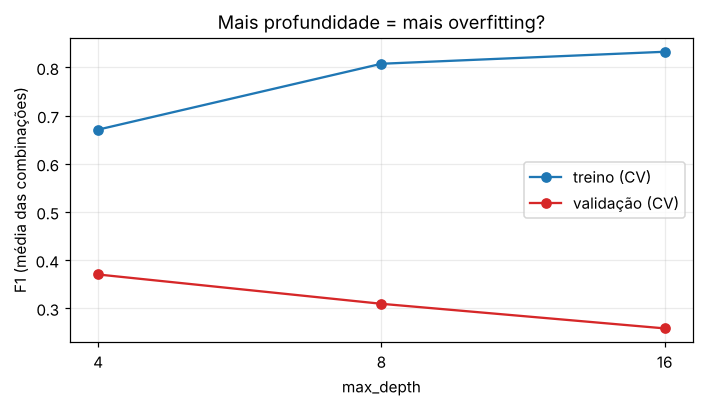

,F1_treino_cv,F1_validacao_cv
max_depth,,
4,0.671,0.370
8,0.808,0.309
16,0.833,0.258


In [9]:
# Overfitting nos hiperparâmetros: F1 treino x validação por profundidade da árvore
por_prof = grid.groupby("max_depth")[["F1_treino_cv", "F1_validacao_cv"]].mean()
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(por_prof.index.astype(str), por_prof["F1_treino_cv"], "o-", label="treino (CV)", color="#1f77b4")
ax.plot(por_prof.index.astype(str), por_prof["F1_validacao_cv"], "o-", label="validação (CV)", color="#d62728")
ax.set_xlabel("max_depth"); ax.set_ylabel("F1 (média das combinações)"); ax.set_title("Mais profundidade = mais overfitting?")
ax.legend(); plt.tight_layout(); plt.savefig(FIG_DIR / "04_overfitting_profundidade.png", bbox_inches="tight"); plt.show()
por_prof.round(3)

## 4. Resultados em treino e teste

O modelo final é o melhor da grade, reajustado em **todo o treino**. O teste (anos mais recentes) só é usado aqui, uma vez.

,Acurácia,Precisão,Recall,F1,ROC-AUC,PR-AUC
Persistência (treino),0.899,0.521,0.521,0.521,0.890,0.530
Persistência (teste),0.944,0.636,0.636,0.636,0.919,0.655
Random Forest (treino),0.905,0.529,0.901,0.667,0.971,0.789
Random Forest (teste),0.930,0.533,0.727,0.615,0.949,0.604


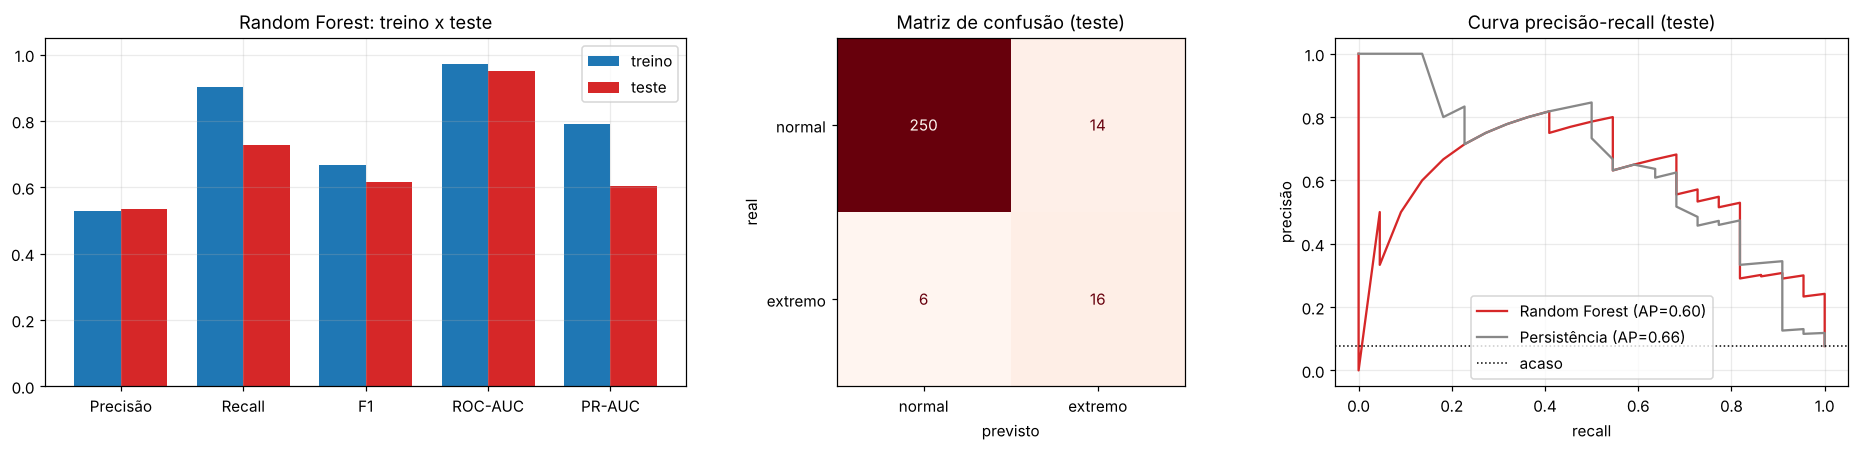

In [10]:
best = gs.best_estimator_
proba_tr, proba_te = best.predict_proba(X_tr)[:, 1], best.predict_proba(X_te)[:, 1]
pred_tr, pred_te = best.predict(X_tr), best.predict(X_te)

def metricas(y, score, pred):
    return {"Acurácia": accuracy_score(y, pred), "Precisão": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0), "F1": f1_score(y, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y, score), "PR-AUC": average_precision_score(y, score)}

base_tr, base_te = (X_tr["tmax"] >= LIMIAR).astype(int), (X_te["tmax"] >= LIMIAR).astype(int)
tab = pd.DataFrame({
    "Persistência (treino)": metricas(y_tr, X_tr["tmax"], base_tr),
    "Persistência (teste)":  metricas(y_te, X_te["tmax"], base_te),
    "Random Forest (treino)": metricas(y_tr, proba_tr, pred_tr),
    "Random Forest (teste)":  metricas(y_te, proba_te, pred_te),
}).T
tab.round(3).to_csv(RES_DIR / "metricas_treino_teste.csv")
display(tab.round(3))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2), gridspec_kw={"width_ratios": [1.5, 1, 1.2]})
cols = ["Precisão", "Recall", "F1", "ROC-AUC", "PR-AUC"]
x = np.arange(len(cols)); w = .38
ax[0].bar(x - w/2, tab.loc["Random Forest (treino)", cols], w, label="treino", color="#1f77b4")
ax[0].bar(x + w/2, tab.loc["Random Forest (teste)", cols], w, label="teste", color="#d62728")
ax[0].set_xticks(x); ax[0].set_xticklabels(cols); ax[0].set_ylim(0, 1.05); ax[0].legend()
ax[0].set_title("Random Forest: treino x teste")
ConfusionMatrixDisplay(confusion_matrix(y_te, pred_te), display_labels=["normal", "extremo"]).plot(ax=ax[1], colorbar=False, cmap="Reds")
ax[1].set_title("Matriz de confusão (teste)"); ax[1].set_xlabel("previsto"); ax[1].set_ylabel("real"); ax[1].grid(False)
p, r, _ = precision_recall_curve(y_te, proba_te); pb, rb, _ = precision_recall_curve(y_te, X_te["tmax"])
ax[2].plot(r, p, color="#d62728", label=f"Random Forest (AP={average_precision_score(y_te, proba_te):.2f})")
ax[2].plot(rb, pb, color="#888", label=f"Persistência (AP={average_precision_score(y_te, X_te['tmax']):.2f})")
ax[2].axhline(y_te.mean(), color="k", ls=":", lw=1, label="acaso"); ax[2].set_xlabel("recall"); ax[2].set_ylabel("precisão")
ax[2].set_title("Curva precisão-recall (teste)"); ax[2].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "05_metricas_treino_teste.png", bbox_inches="tight"); plt.show()

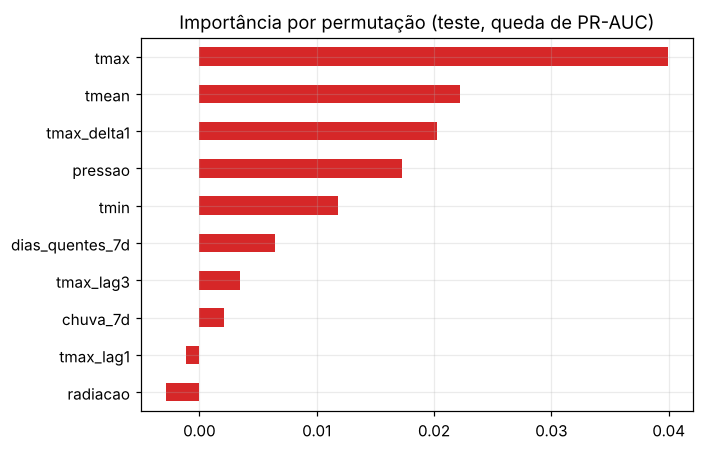

tmax               0.0399
tmean              0.0222
tmax_delta1        0.0202
pressao            0.0173
tmin               0.0118
dias_quentes_7d    0.0064
tmax_lag3          0.0034
chuva_7d           0.0021
tmax_lag1         -0.0011
radiacao          -0.0029
dtype: float64

In [11]:
# Importância das variáveis (permutação no TESTE, mais honesta que a importância interna da floresta)
imp = permutation_importance(best, X_te, y_te, scoring="average_precision", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=FEATURES).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(6.5, 4.2))
imp.head(10).iloc[::-1].plot.barh(ax=ax, color="#d62728")
ax.set_title("Importância por permutação (teste, queda de PR-AUC)"); plt.tight_layout()
plt.savefig(FIG_DIR / "06_importancia_variaveis.png", bbox_inches="tight"); plt.show()
imp.head(10).round(4)

## 5. Conclusão e leitura para o cidadão

Abaixo, os números traduzidos para o dia a dia: quantos dias extremos o modelo avisou, quantos alertas foram falsos e o que cada nível de alerta (verde, amarelo, vermelho) significou na prática.

In [12]:
tn, fp, fn, tp = confusion_matrix(y_te, pred_te).ravel()
anos_teste = len(teste) / 365.25
recall_te, prec_te = recall_score(y_te, pred_te, zero_division=0), precision_score(y_te, pred_te, zero_division=0)
print(f"Teste: {len(teste)} dias ({anos_teste:.1f} anos), {int(y_te.sum())} dias de calor extremo (≥ {LIMIAR:.1f} °C).")
print(f"- O modelo avisou {tp} de {tp + fn} dias extremos com 1 dia de antecedência (recall = {recall_te:.0%}).")
print(f"- De cada 10 alertas, {10 * prec_te:.1f} eram reais (precisão = {prec_te:.0%}).")
print(f"- Dias extremos sem aviso por ano: {fn / anos_teste:.1f}  |  alertas falsos por ano: {fp / anos_teste:.1f}")

NIVEIS = [(0.0, 0.30, "Verde (< 30%)"), (0.30, 0.60, "Amarelo (30–60%)"), (0.60, 1.01, "Vermelho (≥ 60%)")]
linhas = []
for lo, hi, nome in NIVEIS:
    m = (proba_te >= lo) & (proba_te < hi)
    linhas.append({"Nível de alerta": nome, "Dias": int(m.sum()), "Dias extremos reais": int(y_te[m].sum()),
                   "% de dias extremos": f"{100 * y_te[m].mean():.0f}%" if m.sum() else "—"})
alertas = pd.DataFrame(linhas)
alertas.to_csv(RES_DIR / "niveis_de_alerta.csv", index=False)
alertas

Teste: 286 dias (0.8 anos), 22 dias de calor extremo (≥ 32.5 °C).
- O modelo avisou 16 de 22 dias extremos com 1 dia de antecedência (recall = 73%).
- De cada 10 alertas, 5.3 eram reais (precisão = 53%).
- Dias extremos sem aviso por ano: 7.7  |  alertas falsos por ano: 17.9


,Nível de alerta,Dias,Dias extremos reais,% de dias extremos
0,Verde (< 30%),236,4,2%
1,Amarelo (30–60%),28,3,11%
2,Vermelho (≥ 60%),22,15,68%


In [13]:
# Avaliação nos dias de onda de calor (definição operacional): o modelo avisou os dias em que o dia seguinte fez parte de uma onda?
w_op = definicoes[NOME_OP]
onda_amanha = w_op.shift(-1).reindex(teste.index).fillna(False).astype(bool).values
inicio_op = w_op & ~w_op.shift(fill_value=False)
EVENTOS_ONDA_TESTE = int(inicio_op[inicio_op.index >= corte].sum())
N_DIAS_ONDA_TESTE = int(onda_amanha.sum())
if N_DIAS_ONDA_TESTE:
    REC_ONDA_RF, REC_ONDA_BASE = float(pred_te[onda_amanha].mean()), float(base_te.values[onda_amanha].mean())
    print(f"Teste: {N_DIAS_ONDA_TESTE} dias em que o dia seguinte fez parte de uma onda ({EVENTOS_ONDA_TESTE} {'evento' if EVENTOS_ONDA_TESTE == 1 else 'eventos'}).")
    print(f"Avisados pelo modelo: {REC_ONDA_RF:.0%}  |  pela regra simples (hoje ≥ limiar): {REC_ONDA_BASE:.0%}")
else:
    REC_ONDA_RF = REC_ONDA_BASE = np.nan
    print("Não houve dia de onda de calor (nossa definição) no período de teste.")

Teste: 13 dias em que o dia seguinte fez parte de uma onda (2 eventos).
Avisados pelo modelo: 85%  |  pela regra simples (hoje ≥ limiar): 85%


In [14]:
# ----- Números finais do experimento (salvos em resultados/resumo_numeros.json) -----
def br(x):
    """Troca ponto por vírgula só entre dígitos (decimal pt-BR), sem mexer em pontos de frase ou URLs."""
    return re.sub(r"(?<=\d)\.(?=\d)", ",", str(x))

def md_table(df, index=True):
    df = df.reset_index() if index else df
    cab = "| " + " | ".join(map(str, df.columns)) + " |"
    sep = "|" + "|".join(["---"] * len(df.columns)) + "|"
    linhas = ["| " + " | ".join(br(f"{v:.3f}") if isinstance(v, (float, np.floating)) else str(v) for v in row) + " |"
              for row in df.itertuples(index=False)]
    return "\n".join([cab, sep] + linhas)

f1_tr, f1_te = tab.loc["Random Forest (treino)", "F1"], tab.loc["Random Forest (teste)", "F1"]
f1_base = tab.loc["Persistência (teste)", "F1"]
gap = f1_tr - f1_te
cv_tr = grid.loc[grid.ranking == 1, "F1_treino_cv"].iloc[0]; cv_val = grid.loc[grid.ranking == 1, "F1_validacao_cv"].iloc[0]

cv_std = grid.loc[grid.ranking == 1, "desvio_validacao"].iloc[0]
cv_gap = cv_tr - cv_val
if gap >= 0.25:
    l_over = (f"No teste, a diferença de F1 entre treino ({f1_tr:.2f}) e teste ({f1_te:.2f}) é grande ({gap:.2f}): há **overfitting**. "
              "O modelo ajusta bem o passado e perde desempenho em dias novos.")
elif gap >= 0.10:
    l_over = (f"No teste, a diferença de F1 entre treino ({f1_tr:.2f}) e teste ({f1_te:.2f}) é moderada ({gap:.2f}): há algum overfitting, comum em Random Forest.")
elif gap > -0.05:
    l_over = (f"No teste, a diferença de F1 entre treino ({f1_tr:.2f}) e teste ({f1_te:.2f}) é pequena ({gap:.2f}).")
else:
    l_over = (f"No teste, o F1 ({f1_te:.2f}) ficou acima do de treino ({f1_tr:.2f}); isso sugere que o período de teste é mais fácil ou tem outra prevalência de dias extremos.")
if cv_gap >= 0.15:
    l_over += (f" Na validação cruzada temporal, porém, o F1 caiu de {cv_tr:.2f} (treino) para {cv_val:.2f} (validação), com desvio de ±{cv_std:.2f}: "
               "há overfitting ao treino e a estimativa é instável. O número que vale para o cidadão é o do teste.")
else:
    l_over += f" Na validação cruzada temporal, o F1 médio do melhor modelo foi {cv_tr:.2f} no treino e {cv_val:.2f} na validação."

m_rf, m_b = tab.loc["Random Forest (teste)"], tab.loc["Persistência (teste)"]
n_ext_te = int(y_te.sum())
dif = f1_te - f1_base
numeros = (f"No teste, o Random Forest teve F1 {m_rf['F1']:.2f}, recall {m_rf['Recall']:.0%}, ROC-AUC {m_rf['ROC-AUC']:.2f} e PR-AUC {m_rf['PR-AUC']:.2f}; "
           f"a persistência teve F1 {m_b['F1']:.2f}, recall {m_b['Recall']:.0%}, ROC-AUC {m_b['ROC-AUC']:.2f} e PR-AUC {m_b['PR-AUC']:.2f}.")
ganha = [n for n in ("Precisão", "Recall", "ROC-AUC", "PR-AUC") if m_rf[n] - m_b[n] > 0.01]
perde = [n for n in ("Precisão", "Recall", "F1", "ROC-AUC", "PR-AUC") if m_b[n] - m_rf[n] > 0.01]
if dif > 0.02:
    conc = "O Random Forest supera a persistência no F1, então o ML agrega valor além de olhar o dia de hoje."
elif not ganha:
    conc = ("O Random Forest não supera a persistência em nenhuma métrica relevante. É um resultado negativo que registramos: "
            "com estas variáveis, o ML não superou a regra simples.")
elif dif >= -0.02 and not perde:
    conc = "Os dois empatam no F1: o dia de hoje já carrega muita informação e o ganho do ML é pequeno."
else:
    conc = (f"O Random Forest leva vantagem em {', '.join(ganha)} e fica abaixo em {', '.join(perde) or 'nenhuma métrica'}; "
            "a escolha entre os dois depende do custo de deixar de avisar contra o de um alarme falso.")
l_base = f"{numeros} {conc} Com só {n_ext_te} dias extremos no teste, essas diferenças não são conclusivas."

top5 = grid.head(5)
dif_top5 = top5["F1_validacao_cv"].max() - top5["F1_validacao_cv"].min()
l_empate = (f"As 5 melhores combinações diferem em apenas {dif_top5:.2f} de F1, bem menos que o desvio (±{cv_std:.2f}): na prática, é um empate.")
f1 = grid[grid["min_samples_leaf"] == 1]
pior = f1.loc[f1["F1_validacao_cv"].idxmin()]
if (pior["F1_treino_cv"] - pior["F1_validacao_cv"]) > 0.30:
    l_folha = (f"No caso mais extremo (`max_depth`={int(pior['max_depth'])}, `min_samples_leaf`=1), o F1 de treino chegou a {pior['F1_treino_cv']:.2f} "
               f"e o de validação caiu para {pior['F1_validacao_cv']:.2f} (overfitting).")
else:
    l_folha = "Folhas pequenas não causaram overfitting evidente nesta grade."
if N_DIAS_ONDA_TESTE:
    l_onda = (f"No teste, {N_DIAS_ONDA_TESTE} dias tiveram o dia seguinte dentro de uma onda ({EVENTOS_ONDA_TESTE} {'evento' if EVENTOS_ONDA_TESTE == 1 else 'eventos'} de 3 dias seguidos ou mais acima do limiar). "
              f"O modelo avisou {REC_ONDA_RF:.0%} deles e a regra simples, {REC_ONDA_BASE:.0%}. São poucos eventos: é um indício, não uma prova.")
else:
    l_onda = "No período de teste não houve onda de calor pela nossa definição, então não foi possível avaliar esse ponto."
oficial, laranja = ondas.iloc[0], ondas.iloc[1]

valores = {
    "CIDADE": CIDADE, "ESTACAO": ESTACAO, "ESTACAO_DESC": ESTACAO_DESC,
    "PERIODO": f"{d.index.min():%d/%m/%Y} a {d.index.max():%d/%m/%Y}", "N_DIAS": str(len(d)), "N_EXT_TESTE": n_ext_te, "PERIODO_TESTE": f"{teste.index.min():%d/%m/%Y} a {teste.index.max():%d/%m/%Y}",
    "FEATURES": ", ".join(f"`{c}`" for c in FEATURES), "MIN_HORAS": MIN_HORAS_VALIDAS,
    "DATA_CORTE": f"{treino.index.max():%d/%m/%Y}", "N_TREINO": len(treino), "N_TESTE": len(teste),
    "LIMIAR": f"{LIMIAR:.1f}", "PERCENTIL": PERCENTIL_CALOR,
    "PREV_TREINO": f"{y_tr.mean():.1%}", "PREV_TESTE": f"{y_te.mean():.1%}",
    "N_COMBOS": N_COMBOS, "BEST_PARAMS": ", ".join(f"{k}={v}" for k, v in gs.best_params_.items()), "CV_BEST": f"{gs.best_score_:.2f}",
    "TABELA_METRICAS": md_table(tab.round(3).rename_axis("Modelo")),
    "LEITURA_OVERFIT": l_over, "LEITURA_BASELINE": l_base,
    "TOP_FEATURES": ", ".join(f"`{n}` ({v:.3f})" for n, v in imp.head(3).items()),
    "RECALL": f"{recall_te:.0%}", "PRECISION": f"{prec_te:.0%}",
    "FN_ANO": f"{fn / anos_teste:.1f}", "FP_ANO": f"{fp / anos_teste:.1f}",
    "TABELA_ALERTAS": md_table(alertas, index=False),
    "TABELA_COMPACTA": md_table(tab.loc[["Random Forest (treino)", "Random Forest (teste)", "Persistência (teste)"], ["Precisão", "Recall", "F1", "ROC-AUC"]].round(3).rename_axis("Modelo")),
    "N_FEATURES": len(FEATURES), "TEMPATE": l_empate, "OVERFIT_FOLHA1": l_folha, "LEITURA_ONDA": l_onda,
    "EVENTOS_OFICIAL": int(oficial["Eventos no total"]), "EVENTOS_OFICIAL_TESTE": int(oficial["Eventos no teste"]),
    "EVENTOS_LARANJA": int(laranja["Eventos no total"]), "EVENTOS_OP": int(ondas.iloc[2]["Eventos no total"]),
}
(RES_DIR / "resumo_numeros.json").write_text(json.dumps({k: str(v) for k, v in valores.items()}, ensure_ascii=False, indent=2), encoding="utf-8")

print("Números salvos em resultados/resumo_numeros.json")

Números salvos em resultados/resumo_numeros.json
